# Evolução Diferencial (DE) aplicada à função de Rastrigin 2D

Este notebook é o **exemplo de aplicação** do seminário *Uma introdução à Evolução Diferencial*
(Meta-heurísticas 2026/2 — PPGI/UFES). Ele usa a variante clássica **DE/rand/1/bin**
proposta por Storn & Price (1997), implementada na biblioteca [pymoo](https://pymoo.org).

Para cada vetor-alvo $\mathbf{x}_{i,G}$ da população, uma geração do DE executa três operações:

**Mutação** — soma a um vetor-base a diferença ponderada de outros dois vetores:
$$\mathbf{v}_{i,G+1} = \mathbf{x}_{r_1,G} + F\cdot(\mathbf{x}_{r_2,G} - \mathbf{x}_{r_3,G}),\qquad r_1\neq r_2\neq r_3\neq i$$

**Cruzamento binomial** — mistura o vetor mutante com o alvo, coordenada a coordenada:
$$u_{j,i,G+1} = \begin{cases} v_{j,i,G+1} & \text{se } \mathrm{rand}_j \le CR \text{ ou } j = j_{rand}\\ x_{j,i,G} & \text{caso contrário}\end{cases}$$

**Seleção gulosa** — o vetor experimental só entra na próxima geração se for melhor que o alvo:
$$\mathbf{x}_{i,G+1} = \begin{cases} \mathbf{u}_{i,G+1} & \text{se } f(\mathbf{u}_{i,G+1}) < f(\mathbf{x}_{i,G})\\ \mathbf{x}_{i,G} & \text{caso contrário}\end{cases}$$

## 1. Configuração

Os parâmetros do experimento ficam todos nesta célula; altere-os e execute o notebook de novo para ver o efeito.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Image, display

from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.soo.nonconvex.de import DE
from pymoo.optimize import minimize

# ---- Parâmetros do experimento ----
SEED = 42             # semente do pymoo (reprodutibilidade)
D = 2                 # dimensão do problema
NP = 20               # tamanho da população (10·D, faixa sugerida por Storn & Price: 5·D a 10·D)
F = 0.5               # fator de escala da mutação
CR = 0.9              # constante de cruzamento
G_MAX = 100           # número de gerações do DE (além da população inicial)
LIMITE = 5.12         # domínio de busca: [-LIMITE, LIMITE]^D
SEMENTE_EXEMPLO = 6   # semente do exemplo passo a passo da Seção 5

PASTA_FIG = Path("figuras")
PASTA_FIG.mkdir(exist_ok=True)

# ---- Estilo das figuras ----
TINTA, TINTA_2, GRADE = "#0b0b0b", "#52514e", "#e6e5e1"
AZUL, LARANJA = "#2a78d6", "#eb6834"
RAMPA_AZUL = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
              "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
CMAP = LinearSegmentedColormap.from_list("azul_sequencial", RAMPA_AZUL)
CMAP_CLARO = LinearSegmentedColormap.from_list("azul_claro", ["#ffffff"] + RAMPA_AZUL[:6])  # fundo para anotações

plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 9.5, "axes.labelsize": 9,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "grid.color": GRADE, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "legend.frameon": False, "figure.dpi": 110,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white",
})

## 2. O problema: função de Rastrigin

$$f(\mathbf{x}) = 10\,D + \sum_{j=1}^{D}\left[x_j^2 - 10\cos(2\pi x_j)\right],\qquad \mathbf{x}\in[-5{,}12;\ 5{,}12]^D$$

É a função $f_{13}$ do *testbed* de Storn & Price (1997). Ela combina uma parábola com uma
ondulação cossenoidal: em 2D há um mínimo local perto de cada ponto de coordenadas inteiras
(121 no domínio) e um único **mínimo global**, $f(0,0) = 0$. Um método puramente local, partindo
de um ponto aleatório, quase sempre para em um desses mínimos locais — é exatamente o cenário que
motivou o DE.

> O artigo original usa o domínio inicial $[-600, 600]$ para esta função. Aqui usamos o domínio
> usual $[-5{,}12;\ 5{,}12]$ porque ele permite ver a população sobre a paisagem da função.

In [2]:
def rastrigin(x):
    """f(x) = 10·D + Σ (x_j² − 10·cos(2π·x_j)); aceita um vetor ou uma grade (..., D)."""
    x = np.asarray(x, dtype=float)
    return 10 * x.shape[-1] + np.sum(x**2 - 10 * np.cos(2 * np.pi * x), axis=-1)


class Rastrigin(ElementwiseProblem):
    """Rastrigin como problema do pymoo: D variáveis contínuas, 1 objetivo, sem restrições."""

    def __init__(self):
        super().__init__(n_var=D, n_obj=1, xl=-LIMITE, xu=LIMITE)

    def _evaluate(self, x, out, *args, **kwargs):
        out["F"] = rastrigin(x)


# grade usada nos gráficos de curvas de nível
eixo = np.linspace(-LIMITE, LIMITE, 400)
XX, YY = np.meshgrid(eixo, eixo)
ZZ = rastrigin(np.stack([XX, YY], axis=-1))


def desenhar_paisagem(ax, cmap=CMAP):
    """Curvas de nível preenchidas da Rastrigin (claro = f baixo, escuro = f alto)."""
    cf = ax.contourf(XX, YY, ZZ, levels=24, cmap=cmap)
    ax.set_xlim(-LIMITE, LIMITE)
    ax.set_ylim(-LIMITE, LIMITE)
    ax.set_aspect("equal")
    return cf

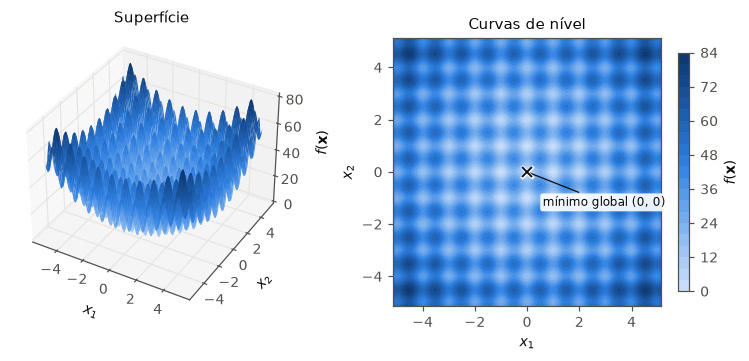

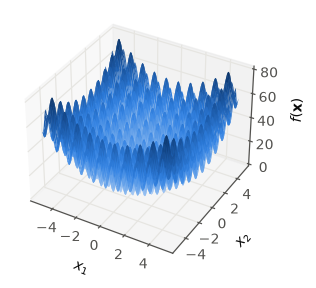

In [3]:
fig = plt.figure(figsize=(7.2, 3.2))
ax3d = fig.add_subplot(1, 2, 1, projection="3d")
ax3d.plot_surface(XX, YY, ZZ, cmap=CMAP, rstride=4, cstride=4, linewidth=0, antialiased=True)
ax3d.set_xlabel("$x_1$", labelpad=-2)
ax3d.set_ylabel("$x_2$", labelpad=-2)
ax3d.set_zlabel("$f(\\mathbf{x})$", labelpad=-2)
ax3d.tick_params(pad=-2)
ax3d.view_init(elev=35, azim=-60)
ax3d.set_title("Superfície")

ax = fig.add_subplot(1, 2, 2)
cf = desenhar_paisagem(ax)
ax.plot(0, 0, marker="x", color="white", ms=8, mew=2.2, zorder=4)
ax.plot(0, 0, marker="x", color=TINTA, ms=7, mew=1.2, zorder=5)
ax.annotate("mínimo global (0, 0)", xy=(0, 0), xytext=(0.6, -1.3), fontsize=8,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9),
            arrowprops=dict(arrowstyle="-", color=TINTA, lw=0.8))
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Curvas de nível")
fig.colorbar(cf, ax=ax, shrink=0.85, label="$f(\\mathbf{x})$")
fig.tight_layout()
fig.savefig(PASTA_FIG / "rastrigin_superficie.png")
plt.show()

# só a superfície, em tamanho menor, para o artigo
fig = plt.figure(figsize=(3.4, 3.0))
ax3d = fig.add_subplot(projection="3d")
ax3d.plot_surface(XX, YY, ZZ, cmap=CMAP, rstride=4, cstride=4, linewidth=0, antialiased=True)
ax3d.set_xlabel("$x_1$", labelpad=-2)
ax3d.set_ylabel("$x_2$", labelpad=-2)
ax3d.set_zlabel("$f(\\mathbf{x})$", labelpad=-2)
ax3d.tick_params(pad=-2)
ax3d.view_init(elev=35, azim=-60)
fig.savefig(PASTA_FIG / "rastrigin_3d.png")
plt.show()

## 3. DE clássico no pymoo

A classe `DE` do pymoo implementa o DE/rand/1/bin, mas alguns padrões dela **não** são os do
algoritmo original. Por isso os parâmetros abaixo são definidos explicitamente:

| Storn & Price (1997) | pymoo | Observação |
|---|---|---|
| DE/rand/1/bin | `variant="DE/rand/1/bin"` | o padrão do pymoo é `DE/best/1/bin` |
| $F = 0{,}5$ constante | `F=0.5, jitter=False` | `jitter=True` perturbaria $F$ a cada vetor |
| $CR = 0{,}9$ | `CR=0.9` | o padrão do pymoo é 0,2 |
| sem outros operadores | `prob_mut=0.0` | o pymoo aplica, por padrão, uma **mutação polinomial** extra (prob. 0,1) após o cruzamento — ela não existe no DE clássico |
| $NP = 20$, inicialização uniforme | `pop_size=20` | amostragem uniforme no domínio (padrão) |
| população nova gerada a partir da atual e depois substituída (Fig. 3 do artigo) | comportamento nativo | todos os vetores experimentais são gerados antes da substituição um a um |

Detalhes de implementação do pymoo que ficam registrados:

- **Limites:** uma coordenada do vetor mutante que sai do domínio é sorteada entre o vetor-base e o limite violado.
- **$j_{rand}$:** se nenhuma coordenada passar no teste $\mathrm{rand}_j \le CR$, o pymoo sorteia uma para vir do mutante. A garantia é a mesma do $j_{rand}$ (ao menos uma coordenada muda), mas o sorteio não é idêntico.
- **Seleção:** usa comparação estrita ($<$) e rejeita vetores experimentais idênticos a membros da população.
- **Gerações:** o pymoo conta a inicialização como geração 1; por isso o critério de parada é `n_gen = G_MAX + 1`.

In [4]:
algoritmo = DE(
    pop_size=NP,
    variant="DE/rand/1/bin",  # vetor-base aleatório, 1 vetor diferença, cruzamento binomial
    F=F,
    CR=CR,
    jitter=False,             # F constante
    prob_mut=0.0,             # desliga a mutação polinomial extra do pymoo
)

res = minimize(Rastrigin(), algoritmo, ("n_gen", G_MAX + 1),
               seed=SEED, save_history=True, verbose=False)

# população e aptidões de cada geração: índice 0 = população inicial
hist_pop = [a.pop.get("X").copy() for a in res.history]
hist_fit = [a.pop.get("F")[:, 0].copy() for a in res.history]
nfe = res.algorithm.evaluator.n_eval

## 4. Resultado

In [5]:
melhor_por_geracao = np.array([f.min() for f in hist_fit])
geracao_1e6 = int(np.argmax(melhor_por_geracao < 1e-6))

print(f"Melhor solução x*      = ({res.X[0]:.3e}, {res.X[1]:.3e})")
print(f"f(x*)                  = {res.F[0]:.3e}")
print(f"Gerações do DE         = {len(hist_pop) - 1}")
print(f"Avaliações de f (nfe)  = {nfe}  (= NP·(G_MAX+1) = {NP}·{G_MAX + 1})")
print(f"1ª geração com f<1e-6  = {geracao_1e6}  ({NP * (geracao_1e6 + 1)} avaliações)")

assert res.F[0] < 1e-6, "o DE não atingiu o mínimo global — aumente G_MAX ou NP"
assert np.allclose(res.X, 0, atol=1e-3)
assert len(hist_pop) == G_MAX + 1 and all(p.shape == (NP, D) for p in hist_pop)
assert nfe == NP * (G_MAX + 1)

Melhor solução x*      = (-2.491e-09, -2.403e-09)
f(x*)                  = 3.553e-15
Gerações do DE         = 100
Avaliações de f (nfe)  = 2020  (= NP·(G_MAX+1) = 20·101)
1ª geração com f<1e-6  = 61  (1240 avaliações)


## 5. Exemplo passo a passo de uma geração

Para mostrar as três operações com números, esta célula repete **manualmente**, em NumPy, o que
o DE faz com um único vetor-alvo da população inicial. O gerador aleatório é próprio (não é o do
pymoo); a semente `SEMENTE_EXEMPLO` foi escolhida para que o exemplo mostre os dois casos do
cruzamento — uma coordenada vinda do mutante e outra herdada do alvo — e um vetor experimental
que vence a seleção.

In [6]:
pop0, fit0 = hist_pop[0], hist_fit[0]
rng_ex = np.random.default_rng(SEMENTE_EXEMPLO)

i = 0                                                    # índice do vetor-alvo
candidatos = [k for k in range(NP) if k != i]
r1, r2, r3 = rng_ex.choice(candidatos, size=3, replace=False)

x_i, x_r1, x_r2, x_r3 = pop0[i], pop0[r1], pop0[r2], pop0[r3]
diferenca = x_r2 - x_r3
v = x_r1 + F * diferenca                                 # mutação

rand_j = rng_ex.random(D)
j_rand = rng_ex.integers(D)
vem_do_mutante = (rand_j <= CR) | (np.arange(D) == j_rand)
u = np.where(vem_do_mutante, v, x_i)                     # cruzamento binomial

f_x, f_u = rastrigin(x_i), rastrigin(u)
vencedor = "u (vetor experimental)" if f_u < f_x else "x_i (alvo)"   # seleção

def fmt(vetor):
    return "(" + ", ".join(f"{c:+.3f}" for c in vetor) + ")"

print(f"alvo       x_{i}      = {fmt(x_i)}   f = {f_x:.3f}")
print(f"base       x_r1 = x_{r1:<2d} = {fmt(x_r1)}")
print(f"           x_r2 = x_{r2:<2d} = {fmt(x_r2)}")
print(f"           x_r3 = x_{r3:<2d} = {fmt(x_r3)}")
print(f"diferença  x_r2 - x_r3 = {fmt(diferenca)}")
print(f"mutante    v = x_r1 + {F}·(x_r2 - x_r3) = {fmt(v)}")
print(f"cruzamento rand_j = {fmt(rand_j)}, j_rand = {j_rand + 1}, CR = {CR}")
for j in range(D):
    origem = "v (mutante)" if vem_do_mutante[j] else "x_i (alvo)"
    print(f"           coordenada {j + 1}: vem de {origem}")
print(f"experimental u = {fmt(u)}   f = {f_u:.3f}")
print(f"seleção    f(u) = {f_u:.3f} {'<' if f_u < f_x else '>='} f(x_i) = {f_x:.3f}  ->  sobrevive {vencedor}")

exemplo = {
    "i": i, "r1": int(r1), "r2": int(r2), "r3": int(r3),
    "x_i": x_i.tolist(), "x_r1": x_r1.tolist(), "x_r2": x_r2.tolist(), "x_r3": x_r3.tolist(),
    "diferenca": diferenca.tolist(), "v": v.tolist(), "rand_j": rand_j.tolist(),
    "j_rand": int(j_rand) + 1, "u": u.tolist(), "f_x": float(f_x), "f_u": float(f_u),
}

alvo       x_0      = (+2.805, -0.626)   f = 31.887
base       x_r1 = x_8  = (+0.559, -4.467)
           x_r2 = x_19 = (-2.796, +1.739)
           x_r3 = x_10 = (+2.643, -1.490)
diferença  x_r2 - x_r3 = (-5.439, +3.229)
mutante    v = x_r1 + 0.5·(x_r2 - x_r3) = (-2.161, -2.852)
cruzamento rand_j = (+0.374, +0.987), j_rand = 1, CR = 0.9
           coordenada 1: vem de v (mutante)
           coordenada 2: vem de x_i (alvo)
experimental u = (-2.161, -0.626)   f = 26.770
seleção    f(u) = 26.770 < f(x_i) = 31.887  ->  sobrevive u (vetor experimental)


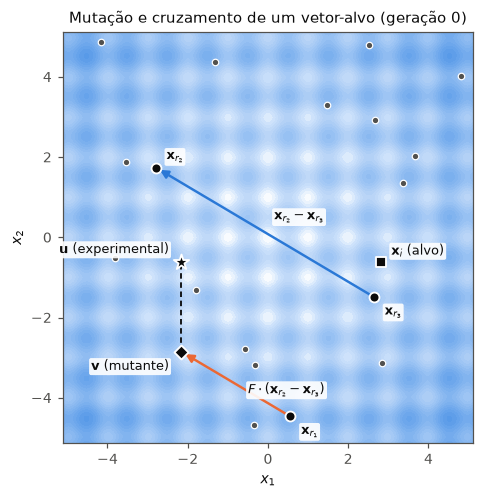

In [7]:
fig, ax = plt.subplots(figsize=(4.6, 4.6))
desenhar_paisagem(ax, cmap=CMAP_CLARO)

outros = [k for k in range(NP) if k not in (i, r1, r2, r3)]
ax.scatter(pop0[outros, 0], pop0[outros, 1], s=18, c=TINTA_2, edgecolors="white",
           linewidths=0.8, zorder=3, label="demais indivíduos")

seta = dict(arrowstyle="-|>", mutation_scale=11, lw=1.6, shrinkA=3, shrinkB=3)
ax.annotate("", xy=x_r2, xytext=x_r3, arrowprops=dict(seta, color=AZUL), zorder=4)
ax.annotate("", xy=v, xytext=x_r1, arrowprops=dict(seta, color=LARANJA), zorder=4)
ax.plot([v[0], u[0]], [v[1], u[1]], ls=(0, (3, 2)), lw=1.2, color=TINTA, zorder=4)

for ponto, marcador in [(x_r1, "o"), (x_r2, "o"), (x_r3, "o"), (x_i, "s"), (v, "D"), (u, "*")]:
    ax.scatter(*ponto, s=110 if marcador == "*" else 42, marker=marcador, c=TINTA,
               edgecolors="white", linewidths=1.2, zorder=5)

caixa = dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9)
# (ponto, texto, deslocamento em pontos, alinhamento horizontal)
rotulos = [(x_i, "$\\mathbf{x}_i$ (alvo)", (7, 5), "left"),
           (x_r1, "$\\mathbf{x}_{r_1}$", (7, -12), "left"),
           (x_r2, "$\\mathbf{x}_{r_2}$", (7, 5), "left"),
           (x_r3, "$\\mathbf{x}_{r_3}$", (7, -12), "left"),
           (v, "$\\mathbf{v}$ (mutante)", (-8, -12), "right"),
           (u, "$\\mathbf{u}$ (experimental)", (-8, 6), "right"),
           ((x_r2 + x_r3) / 2, "$\\mathbf{x}_{r_2}-\\mathbf{x}_{r_3}$", (6, 8), "left"),
           ((x_r1 + v) / 2, "$F\\cdot(\\mathbf{x}_{r_2}-\\mathbf{x}_{r_3})$", (8, -6), "left")]
for ponto, texto, deslocamento, alinhamento in rotulos:
    ax.annotate(texto, xy=ponto, xytext=deslocamento, textcoords="offset points",
                ha=alinhamento, fontsize=8.5, bbox=caixa, zorder=6)

ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Mutação e cruzamento de um vetor-alvo (geração 0)")
fig.tight_layout()
fig.savefig(PASTA_FIG / "mutacao_vetores.png")
plt.show()

## 6. Evolução da população

Os quatro instantes abaixo mostram o comportamento típico do DE: no início a população cobre o
domínio inteiro (**diversificação**); com as gerações, a seleção descarta os indivíduos presos em
mínimos locais ruins e a população se concentra na bacia do mínimo global (**intensificação**).
Como a mutação usa diferenças entre membros da própria população, o tamanho do passo encolhe
automaticamente à medida que a população converge.

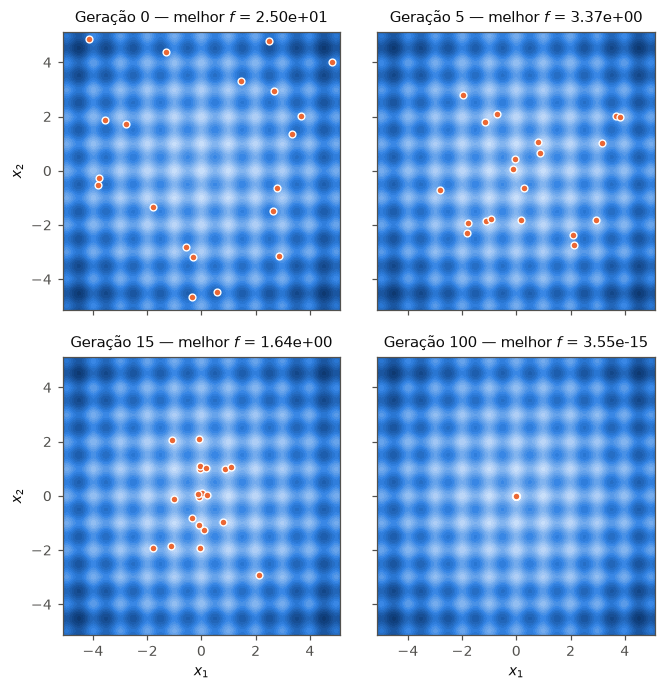

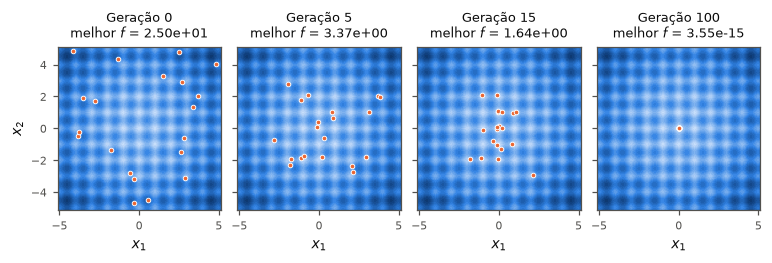

In [8]:
GERACOES = [0, 5, 15, G_MAX]

fig, axs = plt.subplots(2, 2, figsize=(6.2, 6.4), sharex=True, sharey=True)
for ax, g in zip(axs.flat, GERACOES):
    desenhar_paisagem(ax)
    ax.scatter(hist_pop[g][:, 0], hist_pop[g][:, 1], s=20, c=LARANJA,
               edgecolors="white", linewidths=0.9, zorder=3)
    ax.set_title(f"Geração {g} — melhor $f$ = {hist_fit[g].min():.2e}")
for ax in axs[1]:
    ax.set_xlabel("$x_1$")
for ax in axs[:, 0]:
    ax.set_ylabel("$x_2$")
fig.tight_layout()
fig.savefig(PASTA_FIG / "populacao_geracoes.png")
plt.show()

# mesma figura em uma linha (1×4), mais compacta para o artigo
fig, axs = plt.subplots(1, 4, figsize=(7.2, 2.25), sharey=True)
for ax, g in zip(axs, GERACOES):
    desenhar_paisagem(ax)
    ax.scatter(hist_pop[g][:, 0], hist_pop[g][:, 1], s=9, c=LARANJA,
               edgecolors="white", linewidths=0.6, zorder=3)
    ax.set_title(f"Geração {g}\nmelhor $f$ = {hist_fit[g].min():.2e}", fontsize=8.5)
    ax.set_xlabel("$x_1$")
    ax.tick_params(labelsize=7.5)
axs[0].set_ylabel("$x_2$")
fig.tight_layout(w_pad=0.6)
fig.savefig(PASTA_FIG / "populacao_geracoes_linha.png")
plt.show()

## 7. Convergência

À esquerda, o melhor valor e o valor médio de $f$ na população a cada geração. À direita, a
dispersão da população (distância média dos indivíduos ao centroide), que é a escala dos vetores
diferença usados na mutação.

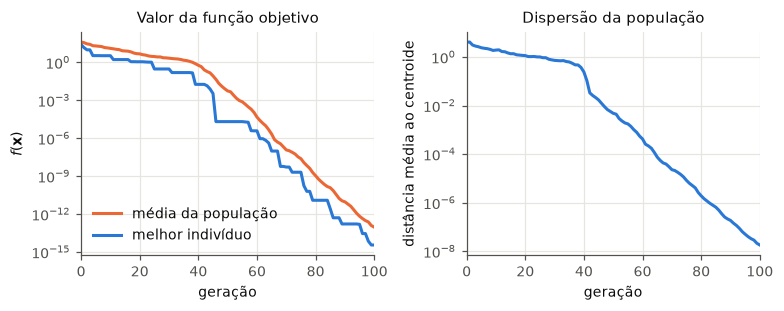

In [9]:
geracoes = np.arange(len(hist_pop))
melhor = np.maximum([f.min() for f in hist_fit], 1e-16)     # piso para a escala log (f pode ser 0)
media = np.maximum([f.mean() for f in hist_fit], 1e-16)
dispersao = np.array([np.linalg.norm(p - p.mean(axis=0), axis=1).mean() for p in hist_pop])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.2, 2.9))
ax1.semilogy(geracoes, media, color=LARANJA, lw=2, label="média da população")
ax1.semilogy(geracoes, melhor, color=AZUL, lw=2, label="melhor indivíduo")
ax1.set_xlabel("geração")
ax1.set_ylabel("$f(\\mathbf{x})$")
ax1.set_title("Valor da função objetivo")
ax1.legend(loc="lower left")

ax2.semilogy(geracoes, dispersao, color=AZUL, lw=2)
ax2.set_xlabel("geração")
ax2.set_ylabel("distância média ao centroide")
ax2.set_title("Dispersão da população")

for ax in (ax1, ax2):
    ax.grid(True, which="major")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlim(0, G_MAX)
fig.tight_layout()
fig.savefig(PASTA_FIG / "convergencia.png")
plt.show()

## 8. Animação da população

O GIF gerado aqui é usado nos slides da apresentação.

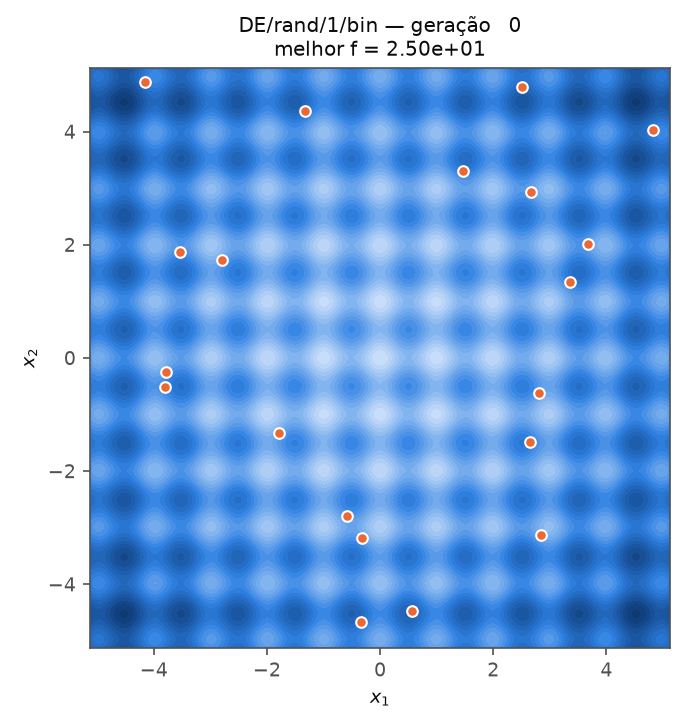

In [10]:
fig, ax = plt.subplots(figsize=(4.6, 4.8), dpi=100)
desenhar_paisagem(ax)
pontos = ax.scatter(hist_pop[0][:, 0], hist_pop[0][:, 1], s=26, c=LARANJA,
                    edgecolors="white", linewidths=1.0, zorder=3)
titulo = ax.set_title("DE/rand/1/bin — geração   0\nmelhor f = 0.00e+00")   # texto provisório: reserva espaço para o título de 2 linhas
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
fig.tight_layout()

def atualizar(g):
    pontos.set_offsets(hist_pop[g])
    titulo.set_text(f"DE/rand/1/bin — geração {g:3d}\nmelhor f = {hist_fit[g].min():.2e}")
    return pontos, titulo

quadros = list(range(len(hist_pop))) + [len(hist_pop) - 1] * 20   # segura o último quadro por 2 s
anim = animation.FuncAnimation(fig, atualizar, frames=quadros, interval=100)
anim.save(PASTA_FIG / "populacao_de.gif", writer=animation.PillowWriter(fps=10), dpi=150)
plt.close(fig)
display(Image(filename=str(PASTA_FIG / "populacao_de.gif")))

## 9. Números para o artigo e os slides

Os resultados são salvos em `resultados.json` para que o texto do artigo e dos slides use exatamente os mesmos valores.

Para descrever a transição entre diversificação e intensificação, contamos também quantas
**bacias de atração** diferentes a população ocupa em cada geração. Na Rastrigin, cada mínimo local
fica perto de um ponto de coordenadas inteiras, então arredondar a posição de um indivíduo indica
(aproximadamente) em qual bacia ele está.

In [11]:
bacias = [len({tuple(np.round(x).astype(int)) for x in pop}) for pop in hist_pop]
geracao_bacia_unica = next(g for g, b in enumerate(bacias) if b == 1)
for g in [0, 5, 15, 25, 35, geracao_bacia_unica]:
    print(f"geração {g:3d}: {bacias[g]:2d} bacia(s) ocupada(s), melhor f = {hist_fit[g].min():.3g}")

geração   0: 19 bacia(s) ocupada(s), melhor f = 25
geração   5: 14 bacia(s) ocupada(s), melhor f = 3.37
geração  15: 12 bacia(s) ocupada(s), melhor f = 1.64
geração  25:  9 bacia(s) ocupada(s), melhor f = 0.296
geração  35:  3 bacia(s) ocupada(s), melhor f = 0.154
geração  42:  1 bacia(s) ocupada(s), melhor f = 0.018


In [12]:
resultados = {
    "parametros": {"SEED": SEED, "D": D, "NP": NP, "F": F, "CR": CR, "G_MAX": G_MAX, "LIMITE": LIMITE},
    "x_otimo": res.X.tolist(),
    "f_otimo": float(res.F[0]),
    "nfe": int(nfe),
    "geracao_f_menor_1e6": geracao_1e6,
    "nfe_f_menor_1e6": NP * (geracao_1e6 + 1),
    "melhor_f_geracoes": {g: float(hist_fit[g].min()) for g in GERACOES},
    "dispersao_inicial": float(dispersao[0]),
    "dispersao_final": float(dispersao[-1]),
    "bacias_ocupadas": {g: bacias[g] for g in [0, 5, 15, 25, 35, geracao_bacia_unica]},
    "geracao_bacia_unica": geracao_bacia_unica,
    "exemplo_passo_a_passo": exemplo,
}
Path("resultados.json").write_text(json.dumps(resultados, indent=2, ensure_ascii=False))
print(json.dumps(resultados, indent=2, ensure_ascii=False))

{
  "parametros": {
    "SEED": 42,
    "D": 2,
    "NP": 20,
    "F": 0.5,
    "CR": 0.9,
    "G_MAX": 100,
    "LIMITE": 5.12
  },
  "x_otimo": [
    -2.4909726166973902e-09,
    -2.403086343479739e-09
  ],
  "f_otimo": 3.552713678800501e-15,
  "nfe": 2020,
  "geracao_f_menor_1e6": 61,
  "nfe_f_menor_1e6": 1240,
  "melhor_f_geracoes": {
    "0": 25.006829246673,
    "5": 3.3684290701904303,
    "15": 1.6409247715614868,
    "100": 3.552713678800501e-15
  },
  "dispersao_inicial": 4.021377909101497,
  "dispersao_final": 1.8089267315062024e-08,
  "bacias_ocupadas": {
    "0": 19,
    "5": 14,
    "15": 12,
    "25": 9,
    "35": 3,
    "42": 1
  },
  "geracao_bacia_unica": 42,
  "exemplo_passo_a_passo": {
    "i": 0,
    "r1": 8,
    "r2": 19,
    "r3": 10,
    "x_i": [
      2.8053099372130648,
      -0.6258847769389844
    ],
    "x_r1": [
      0.558948219042148,
      -4.466511297493245
    ],
    "x_r2": [
      -2.7964482657189467,
      1.7388953055489056
    ],
    "x_r3": [
  

## 10. Comentários finais

- O DE/rand/1/bin encontrou o mínimo global da Rastrigin 2D, uma função com 121 mínimos locais no
  domínio, usando apenas avaliações de $f$ (sem gradiente) e três parâmetros de controle
  ($NP$, $F$, $CR$) nos valores recomendados por Storn & Price (1997).
- As figuras mostram a transição de **diversificação** para **intensificação**: a dispersão da
  população cai várias ordens de grandeza, e com ela o tamanho dos vetores diferença — o DE ajusta
  o próprio passo sem nenhum parâmetro adicional.
- Experimente alterar `F`, `CR` ou `NP` na célula de configuração: valores pequenos de `F` ou de
  `NP` tendem a acelerar a convergência, mas aumentam o risco de a população convergir para um
  mínimo local.